# SAM 2 for Roman Space Telescope: Tutorial 06
## Full-Image Astronomical Inference with Boundary-Aware UNet++ & LeakySB Visualization

This interactive tutorial demonstrates how to load an astronomical **FITS** (or Roman **ASDF**) image, run promptless deep learning segmentation using a fine-tuned **UNet++ (Nested U-Net)** checkpoint, and render publication-quality side-by-side diagnostic figures.

### Key Workflow Highlights:
1. **Unified Astronomical I/O**: Ingesting raw scientific exposures (.fits, .fits.gz, .asdf) and reading astronomical metadata and celestial WCS headers (`sam2roman.io.load_astro_image`).
2. **Photometric Surface Brightness Stretch (`leakySB`)**: Applying non-linear transformations preserving dynamic range across bright stellar cores while revealing faint galaxy wings.
3. **Hardware Acceleration**: Automatic deployment on **Apple Silicon MPS**, **NVIDIA CUDA** (with TF32 & bfloat16 AMP), or **CPU**.
4. **Tiled Sliding-Window Inference (`predict_dense`)**: Seamless 2D inference with cosine window blending that processes arbitrary image sizes (from $512 \times 512$ cutouts up to $4088 \times 4088$ Roman WFI detectors) with bounded GPU memory.
5. **High-Contrast 2-Panel Visualization**: Side-by-side display of the LeakySB astronomical image and the boundary-aware 3-class segmentation prediction (Sky Background, Source Interior, Deblending Boundary).
6. **High-Resolution Cutout Zoom**: Inspecting fine morphological boundaries and touching-source deblending.
7. **Astronomical Instance Extraction (`segment_image`)**: Converting dense pixel predictions into labeled object catalogs using marker-controlled watershed deblending.

### Google Colab / Remote Cloud Setup (Optional)
If running this notebook in Google Colab or a remote cloud environment, uncomment and run the cell below:

In [1]:
# In Google Colab, uncomment and run:
# !nvidia-smi
# !git clone https://github.com/PabloMSanAla/sam2roman.git
# %cd sam2roman
# !pip install -e .
#
# If your Roman data and checkpoints are in Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')

### Step 1: Import Modules & Auto-Detect Hardware Accelerator

We import `sam2roman`, PyTorch, NumPy, and Matplotlib. Hardware acceleration is auto-detected:
- **Apple Silicon (MPS)**: Metal Performance Shaders for local macOS development.
- **NVIDIA GPU (CUDA)**: TF32 and AMP bfloat16 optimization for datacenter GPUs.
- **CPU**: Standard fallback.

In [2]:
import os
import sys
import time
from pathlib import Path

# Ensure sam2roman package is accessible
for p in ['/content/sam2roman/src', 'src', '../src', '../../src']:
    resolved = Path(p).resolve()
    if resolved.exists() and str(resolved) not in sys.path:
        sys.path.insert(0, str(resolved))
        break

# Enable inline plotting
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import numpy as np
import torch

from sam2roman.io.reader import load_astro_image
from sam2roman.io.fits import FITSImage, stretch_astro_image
from sam2roman.inference.unetpp_segmentor import UNetPPSegmentor
from sam2roman.visualization.display import plot_two_panel_prediction, plot_masks_overlay

# Hardware accelerator auto-detection
if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"[Hardware] Accelerator: {gpu_name} ({vram_gb:.1f} GB VRAM)")
    print(f"  -> CUDA active: TF32=True, AMP (bfloat16) enabled")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f"[Hardware] Accelerator: Apple Silicon MPS (Metal Performance Shaders active)")
else:
    device = torch.device("cpu")
    print(f"[Hardware] Accelerator: CPU")

W1030 23:03:55.144000 9707 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


[Hardware] Accelerator: Apple Silicon MPS (Metal Performance Shaders active)


### Step 2: Configure Image and Checkpoint Paths

Specify the path to your astronomical FITS image and fine-tuned UNet++ model checkpoint.
The code below provides smart fallbacks that automatically search:
- Dedicated synthetic training fields (`sample_data/sample_roman_train_field.fits`)
- Full Roman WFI 4088x4088 exposures on external storage (`/Volumes/T7/...`)
- Checkpoints from GH200 / local training (`experiments/unet/test_1/unetpp_best.pt` or `tutorials/checkpoints/unetpp_best.pt`)

In [3]:
# 1. Candidate Checkpoints (edit or leave automatic)
ckpt_candidates = [
    Path("experiments/unet/test_1/unetpp_best.pt"),
    Path("../experiments/unet/test_1/unetpp_best.pt"),
    Path("../../experiments/unet/test_1/unetpp_best.pt"),
    Path("checkpoints/unetpp_best.pt"),
    Path("tutorials/checkpoints/unetpp_best.pt"),
    Path("../tutorials/checkpoints/unetpp_best.pt"),
]

CHECKPOINT_PATH = None
for cand in ckpt_candidates:
    if cand.exists():
        CHECKPOINT_PATH = cand.resolve()
        break

if CHECKPOINT_PATH is None:
    raise FileNotFoundError(
        "Could not find a UNet++ checkpoint. Please specify CHECKPOINT_PATH manually."
    )

# 2. Candidate Astronomical Images (FITS or ASDF)
image_candidates = [
    Path("tutorials/sample_data/sample_roman_train_field.fits"),
    Path("../tutorials/sample_data/sample_roman_train_field.fits"),
    Path("sample_data/sample_roman_train_field.fits"),
    Path("/Volumes/T7/storage/ROMAN/synthetic_romanisim_sam2/images/scene_0001_F106_detector_01.fits"),
]

FITS_PATH = None
for cand in image_candidates:
    if cand.exists():
        FITS_PATH = cand.resolve()
        break

if FITS_PATH is None:
    raise FileNotFoundError(
        "Could not find an astronomical FITS image. Please specify FITS_PATH manually."
    )

print(f"[Config] Checkpoint: {CHECKPOINT_PATH}")
print(f"[Config] FITS Image: {FITS_PATH}")

[Config] Checkpoint: /Users/pmsanch1/code/sam2roman/experiments/unet/test_1/unetpp_best.pt
[Config] FITS Image: /Users/pmsanch1/code/sam2roman/tutorials/sample_data/sample_roman_train_field.fits


### Step 3: Load FITS Image & Examine Astronomical Metadata

Using `sam2roman.io.load_astro_image`, we ingest the FITS exposure (or Roman ASDF file) and inspect:
- Image pixel dimensions $(H, W)$
- Dynamic range and statistical moments (median sky background, standard deviation, 99th percentile flux)
- Celestial World Coordinate System (WCS) metadata, if present.

In [4]:
astro_img = load_astro_image(FITS_PATH)
raw_data = astro_img.data
h, w = raw_data.shape

print("=" * 60)
print(f"File Name:        {FITS_PATH.name}")
print(f"Dimensions:       {w} × {h} pixels ({w * h / 1e6:.2f} Megapixels)")
print(f"Data Type:        {raw_data.dtype}")
print(f"Flux Min:         {np.nanmin(raw_data):.4f}")
print(f"Flux Max:         {np.nanmax(raw_data):.4f}")
print(f"Flux Median:      {np.nanmedian(raw_data):.4f}")
print(f"Flux Std Dev:     {np.nanstd(raw_data):.4f}")
print(f"Flux 99th %:      {np.nanpercentile(raw_data, 99):.4f}")

if astro_img.wcs is not None:
    print(f"WCS:              Present")
    try:
        center_sky = astro_img.pixel_to_world(w / 2, h / 2)
        print(f"Field Center:     RA = {center_sky.ra.deg:.5f}°, Dec = {center_sky.dec.deg:.5f}°")
    except Exception as e:
        print(f"Field Center:     (WCS coordinate conversion skipped: {e})")
else:
    print(f"WCS:              Not present (pixel coordinates only)")
print("=" * 60)

File Name:        sample_roman_train_field.fits
Dimensions:       1024 × 1024 pixels (1.05 Megapixels)
Data Type:        float32
Flux Min:         -7.9906
Flux Max:         132083.0000
Flux Median:      3.4218
Flux Std Dev:     497.2966
Flux 99th %:      780.7488
WCS:              Present
Field Center:     (WCS coordinate conversion skipped: 'FITSImage' object has no attribute 'pixel_to_world')


### Step 4: Apply Photometric LeakySB Surface Brightness Stretch

Standard linear scaling fails on astronomical imaging because bright stellar point-spread functions (PSFs) can be $10^5\times$ brighter than faint diffuse galaxy wings.
The **Leaky Surface Brightness (`leakySB`)** stretch maps astronomical fluxes to $[0, 1]$ using physical calibrated parameters:
- `zero_points = 31.4` (Roman WFI default)
- `pixel_scale = 0.11` arcsec/pixel
- `mmin = 13.0`, `mmax = 32.0` (mag/arcsec$^2$ limits)

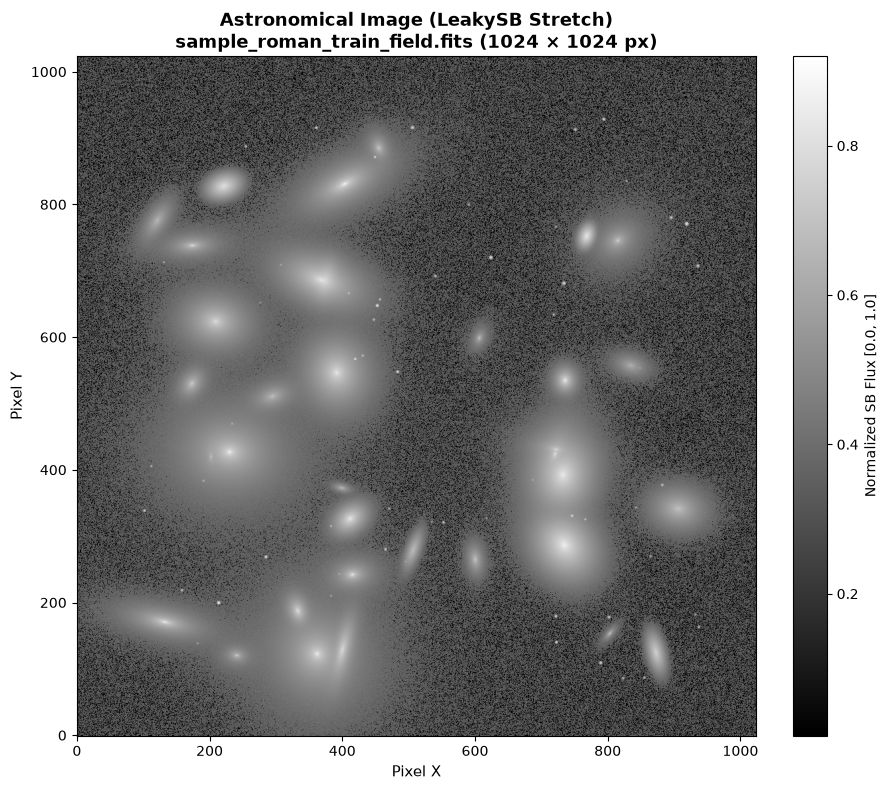

In [5]:
stretched = stretch_astro_image(
    raw_data,
    stretch_type="leakysb",
    zero_points=31.4,
    pixel_scale=0.11,
    mmin=13.0,
    mmax=32.0,
)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(stretched, cmap="gray", origin="lower")
ax.set_title(f"Astronomical Image (LeakySB Stretch)\n{FITS_PATH.name} ({w} × {h} px)", fontsize=13, fontweight="bold")
ax.set_xlabel("Pixel X", fontsize=11)
ax.set_ylabel("Pixel Y", fontsize=11)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Normalized SB Flux [0.0, 1.0]", fontsize=10)
plt.tight_layout()
plt.show()

### Step 5: Load Fine-Tuned UNet++ Model from Checkpoint

We instantiate `UNetPPSegmentor.from_checkpoint()`. The segmentor reads the network configuration (channels, feature maps, deep supervision) and loads the trained weights directly onto the selected accelerator (`mps`, `cuda`, or `cpu`).

In [6]:
print(f"Loading UNet++ checkpoint from: {CHECKPOINT_PATH.name}...")
segmentor = UNetPPSegmentor.from_checkpoint(CHECKPOINT_PATH, device=device)

num_params = sum(p.numel() for p in segmentor.model.parameters())
trainable_params = sum(p.numel() for p in segmentor.model.parameters() if p.requires_grad)

print(f"UNet++ model loaded successfully on {segmentor.device}!")
print(f"Total Parameters:     {num_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Loading UNet++ checkpoint from: unetpp_best.pt...


UNet++ model loaded successfully on mps!
Total Parameters:     9,159,747
Trainable Parameters: 9,159,747


### Step 6: Full-Image Dense Inference (`predict_dense`)

We execute dense inference across the image using `segmentor.predict_dense()`.
- **Tiling**: Slices the image into $512 \times 512$ pixel patches with 64-pixel overlap.
- **Cosine Blending**: Adjacent overlapping tiles are blended using a 2D Hann/cosine window, completely eliminating seam artifacts along tile borders.
- **Bounded Memory**: Memory footprint remains small ($< 350$ MB VRAM) whether running on a $1024 \times 1024$ cutout or a full $4088 \times 4088$ Roman WFI exposure.

The model outputs 3 classes:
- **Class 0 (Sky Background)**
- **Class 1 (Source Interior / Core)**
- **Class 2 (Deblending Boundary / Edge)**

In [7]:
# Tile settings
TILE_SIZE = 512
OVERLAP = 64
BATCH_SIZE = 2

print(f"Starting dense inference on {w} × {h} image...")
t0 = time.time()
pred_mask, probs, stretched_img = segmentor.predict_dense(
    image=FITS_PATH,
    tile_size=TILE_SIZE,
    overlap=OVERLAP,
    batch_size=BATCH_SIZE,
    stretch_type="leakysb",
    verbose=True,
)
inference_time = time.time() - t0

total_px = pred_mask.size
n_sky = int(np.sum(pred_mask == 0))
n_core = int(np.sum(pred_mask == 1))
n_edge = int(np.sum(pred_mask == 2))

print("\n" + "=" * 55)
print(f"Inference Time:             {inference_time:.2f} seconds")
print(f"Predicted Mask Dimensions:  {pred_mask.shape} (dtype: {pred_mask.dtype})")
print(f"Probability Map Shape:      {probs.shape} (dtype: {probs.dtype})")
print("-" * 55)
print(f"Class 0 (Sky Background):   {n_sky:>10,} px ({100.0 * n_sky / total_px:6.2f}%)")
print(f"Class 1 (Source Interior):  {n_core:>10,} px ({100.0 * n_core / total_px:6.2f}%)")
print(f"Class 2 (Deblending Edge):  {n_edge:>10,} px ({100.0 * n_edge / total_px:6.2f}%)")
print("=" * 55)

Starting dense inference on 1024 × 1024 image...
[sam2roman] Starting tiled UNet++ inference: 1024x1024 across 3x3 = 9 tiles (tile_size=512, overlap=64, batch_size=2) on mps...


[sam2roman]   -> Progress: batch 5/5 (9/9 tiles processed)


[sam2roman] Tiled UNet++ inference completed in 1.27s (9 tiles, 141.6ms/tile).



Inference Time:             1.28 seconds
Predicted Mask Dimensions:  (1024, 1024) (dtype: uint8)
Probability Map Shape:      (3, 1024, 1024) (dtype: float32)
-------------------------------------------------------
Class 0 (Sky Background):      905,832 px ( 86.39%)
Class 1 (Source Interior):      20,425 px (  1.95%)
Class 2 (Deblending Edge):     122,319 px ( 11.67%)


### Step 7: Side-by-Side 2-Panel Visualization (LeakySB vs UNet++ Prediction)

Using `plot_two_panel_prediction`, we render a high-contrast side-by-side comparison:
- **Left Panel**: LeakySB-stretched astronomical image.
- **Right Panel**: Discrete 3-class segmentation mask:
  - **Dark Navy/Charcoal (`#0b0d1b`)**: Sky Background (0)
  - **Electric Cyan (`#00d4ff`)**: Source Interior / Core (1)
  - **Vivid Coral Red (`#ff3366`)**: Deblending Boundary / Edge (2)

The axes are linked so panning or zooming in an interactive viewer keeps both panels aligned!

Figure saved to: /Users/pmsanch1/code/sam2roman/tutorials/unetpp_fits_inference_results.png


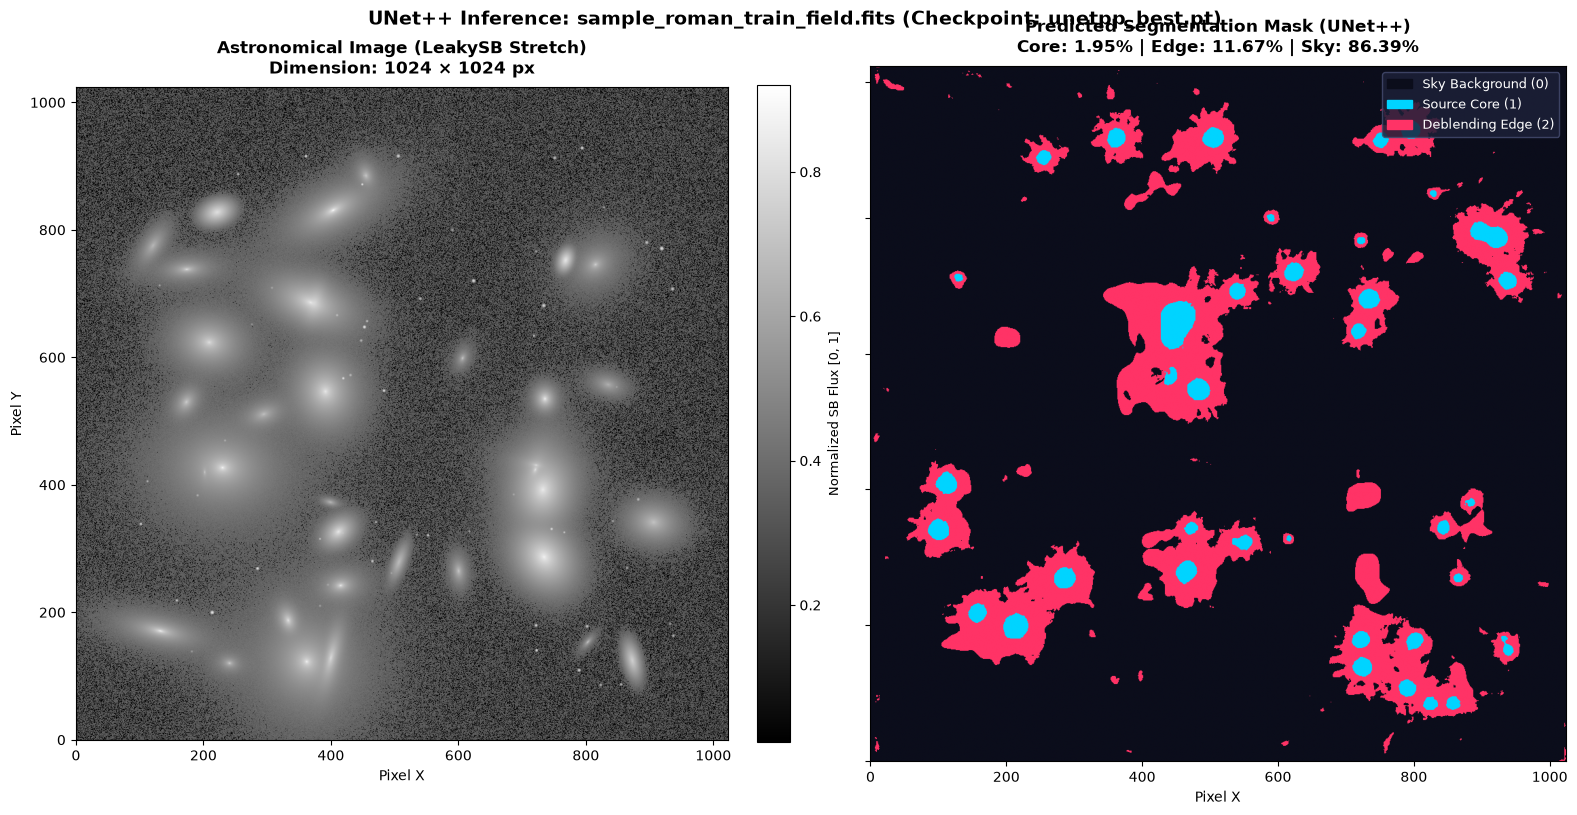

In [8]:
output_figure = Path("unetpp_fits_inference_results.png")

fig = plot_two_panel_prediction(
    stretched=stretched_img,
    pred_mask=pred_mask,
    title=f"UNet++ Inference: {FITS_PATH.name} (Checkpoint: {CHECKPOINT_PATH.name})",
    save_path=output_figure,
    figsize=(16, 8),
    dpi=150,
)

print(f"Figure saved to: {output_figure.resolve()}")
plt.show()

### Step 8: High-Resolution Cutout Zoom — Inspecting Deblending Boundaries

In crowded astronomical fields, overlapping or touching galaxies present a classic deblending challenge. Standard thresholding merges them into a single clump.
Here, we zoom into an active region of detected sources to examine:
1. **LeakySB Cutout**: Raw surface brightness distribution.
2. **Soft Probabilities**: Continuous RGB composite ($P_{\text{core}}$ as Cyan, $P_{\text{edge}}$ as Red).
3. **Discrete Prediction**: The network's 1-to-2 pixel boundary separating touching objects.

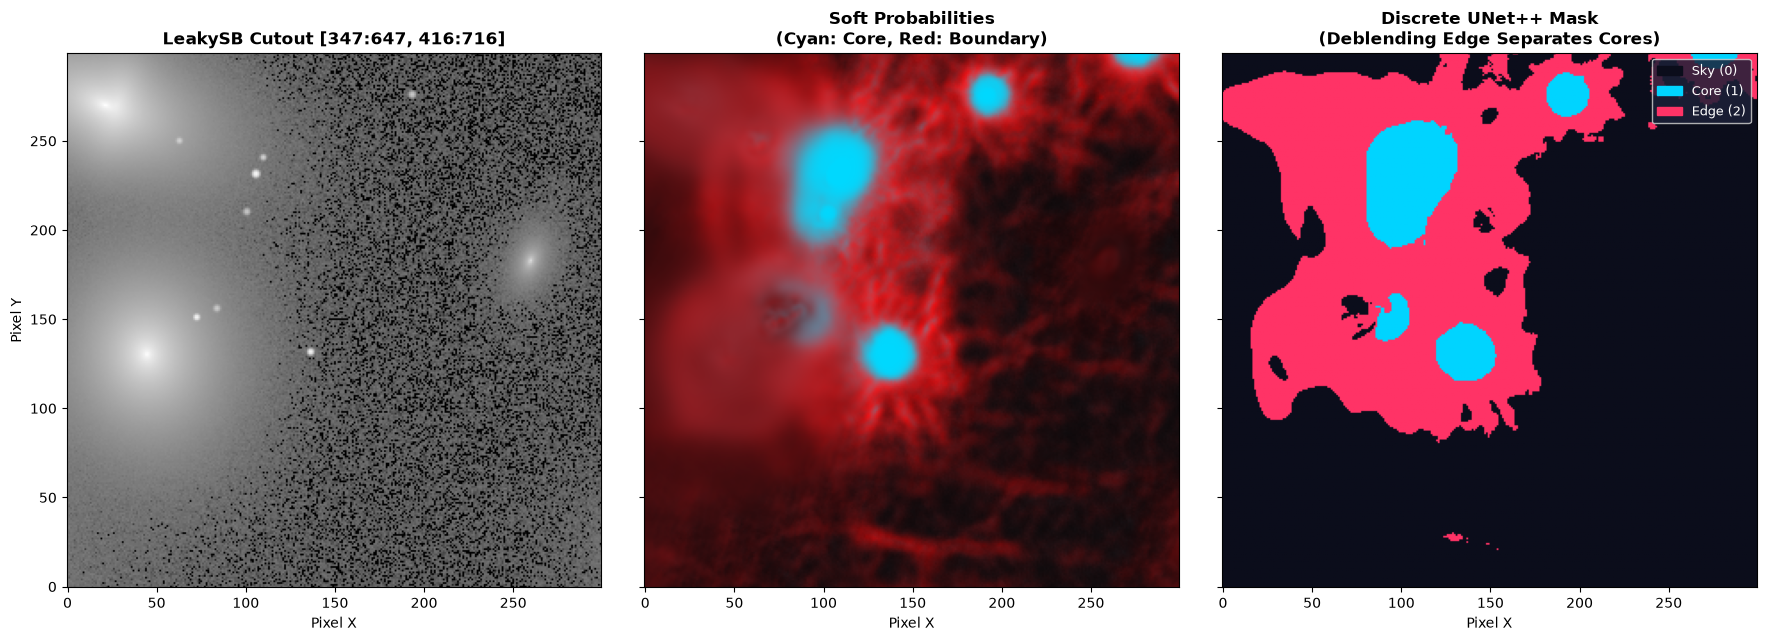

In [9]:
# Automatically find a high-density subregion
y_idx, x_idx = np.where(pred_mask == 1)

if len(y_idx) > 0:
    cy, cx = int(np.median(y_idx)), int(np.median(x_idx))
    half_box = 150
    y0 = max(0, min(h - 2 * half_box, cy - half_box))
    y1 = min(h, y0 + 2 * half_box)
    x0 = max(0, min(w - 2 * half_box, cx - half_box))
    x1 = min(w, x0 + 2 * half_box)
else:
    y0, y1, x0, x1 = 0, min(h, 300), 0, min(w, 300)

cutout_img = stretched_img[y0:y1, x0:x1]
cutout_mask = pred_mask[y0:y1, x0:x1]
cutout_p_core = probs[1, y0:y1, x0:x1]
cutout_p_edge = probs[2, y0:y1, x0:x1]

# Colormaps
cmap_3class = ListedColormap(["#0b0d1b", "#00d4ff", "#ff3366"])
norm_3class = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_3class.N)

# Soft probability composite: Red = Edge, Cyan = Core
prob_composite = np.zeros((cutout_img.shape[0], cutout_img.shape[1], 3), dtype=np.float32)
prob_composite[:, :, 0] = np.clip(cutout_p_edge * 1.2, 0.0, 1.0)        # Red channel
prob_composite[:, :, 1] = np.clip(cutout_p_core * 0.85, 0.0, 1.0)       # Green channel
prob_composite[:, :, 2] = np.clip(cutout_p_core * 1.0, 0.0, 1.0)        # Blue channel

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# Cutout 1: LeakySB
axes[0].imshow(cutout_img, cmap="gray", origin="lower")
axes[0].set_title(f"LeakySB Cutout [{x0}:{x1}, {y0}:{y1}]", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Pixel X")
axes[0].set_ylabel("Pixel Y")

# Cutout 2: Soft Probabilities
axes[1].imshow(prob_composite, origin="lower")
axes[1].set_title("Soft Probabilities\n(Cyan: Core, Red: Boundary)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Pixel X")

# Cutout 3: Discrete Prediction
axes[2].imshow(cutout_mask, cmap=cmap_3class, norm=norm_3class, origin="lower")
axes[2].set_title("Discrete UNet++ Mask\n(Deblending Edge Separates Cores)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Pixel X")

# Add legend to third panel
patches = [
    mpatches.Patch(color="#0b0d1b", label="Sky (0)"),
    mpatches.Patch(color="#00d4ff", label="Core (1)"),
    mpatches.Patch(color="#ff3366", label="Edge (2)"),
]
axes[2].legend(handles=patches, loc="upper right", framealpha=0.85, facecolor="#1c2038", labelcolor="white", fontsize=9)

plt.tight_layout()
plt.show()

### Step 9: Extract Discrete Source Instances & Photometry (`segment_image`)

While `predict_dense()` outputs continuous pixel classes, scientific workflows require **discrete object instances** (individual stars and galaxies) with bounding boxes, centroids, and photometry.
`UNetPPSegmentor.segment_image()` uses the predicted interior cores as topological seed markers and expands them via marker-controlled watershed within the foreground boundary.

Running marker-controlled watershed deblending...


[sam2roman] UNet++ segmented (1024x1024) in 836.6ms (forward pass: 556.4ms on mps). Extracted 40 sources.
Extracted 40 distinct astronomical sources in 0.84s!

Sample Extracted Sources (First 8):
ID   Centroid (X, Y)        BBox [x0, y0, x1, y1]      Area (px)  Score   
---------------------------------------------------------------------------
1    ( 520.4,  478.1)      [0.0, 0.0, 1023.0, 1023.0] 143802      0.638
2    ( 859.4,   85.5)      [830.0, 74.0, 883.0, 103.0] 709         0.891
3    ( 791.5,  106.3)      [778.0, 91.0, 807.0, 123.0] 746         0.959
4    ( 729.0,  138.6)      [710.0, 123.0, 753.0, 163.0] 1017        0.937
5    ( 938.9,  164.3)      [928.0, 153.0, 949.0, 176.0] 388         0.928
6    ( 801.7,  175.4)      [787.0, 158.0, 818.0, 189.0] 695         0.945
7    ( 723.1,  176.6)      [709.0, 153.0, 737.0, 200.0] 890         0.944
8    ( 933.4,  179.3)      [927.0, 172.0, 941.0, 185.0] 119         0.887


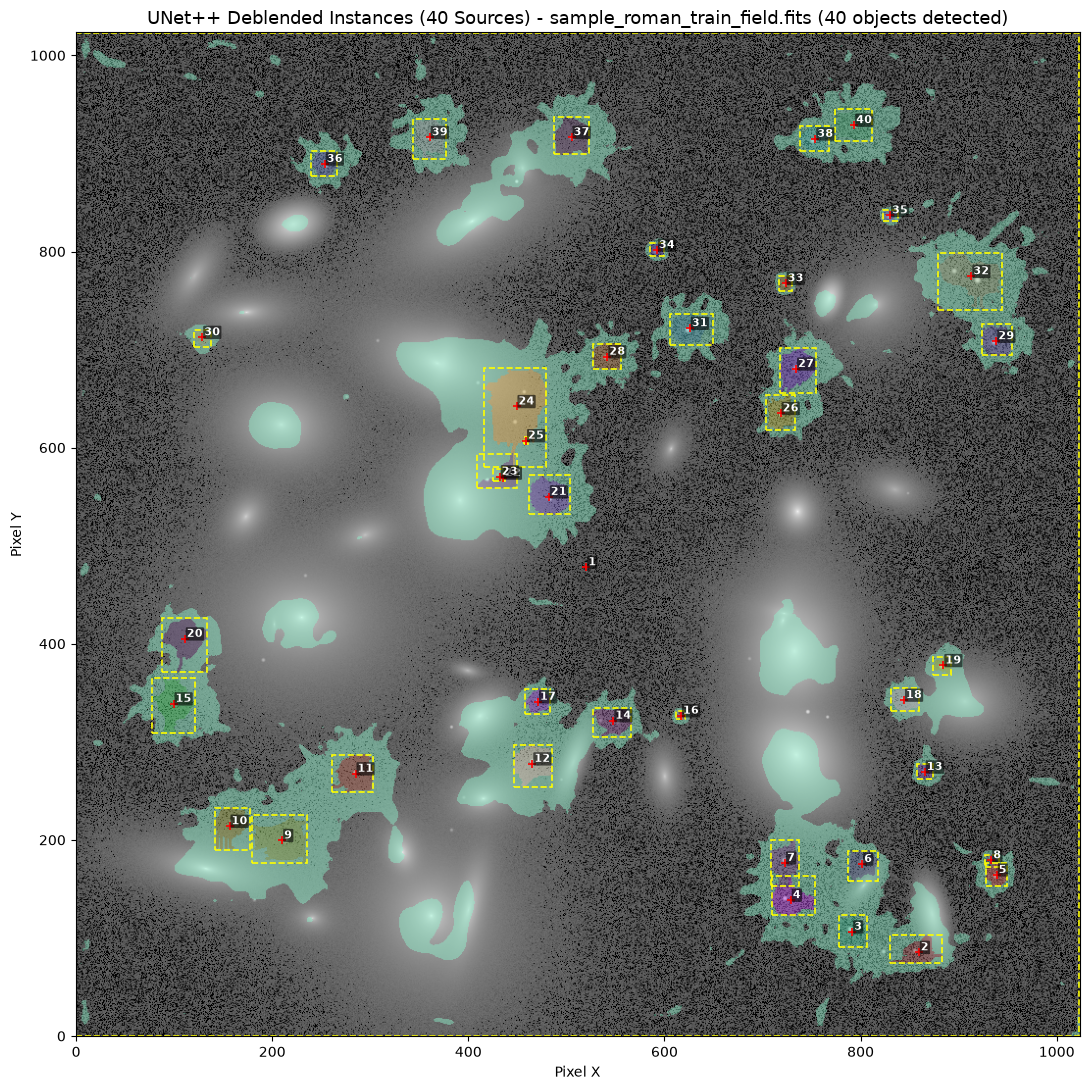

In [10]:
print("Running marker-controlled watershed deblending...")
t_seg = time.time()
res = segmentor.segment_image(
    image=FITS_PATH,
    stretch_type="leakysb",
    interior_thresh=0.45,
    fg_thresh=0.50,
    min_area=10,
    verbose=True,
)
seg_time = time.time() - t_seg

print(f"Extracted {len(res.masks)} distinct astronomical sources in {seg_time:.2f}s!")

if len(res.masks) > 0:
    print("\nSample Extracted Sources (First 8):")
    print(f"{'ID':<4} {'Centroid (X, Y)':<22} {'BBox [x0, y0, x1, y1]':<26} {'Area (px)':<10} {'Score':<8}")
    print("-" * 75)
    for i in range(min(8, len(res.masks))):
        cx, cy = res.centroids[i]
        b = [round(float(v), 1) for v in res.boxes[i]]
        area = int(np.sum(res.masks[i]))
        sc = float(res.scores[i])
        print(f"{i+1:<4} ({cx:6.1f}, {cy:6.1f})      {str(b):<26} {area:<10} {sc:6.3f}")

    # Plot instance overlay
    fig_overlay = plot_masks_overlay(
        image=raw_data,
        masks=res.masks,
        boxes=res.boxes,
        centroids=res.centroids,
        stretch_type="leakysb",
        title=f"UNet++ Deblended Instances ({len(res.masks)} Sources) - {FITS_PATH.name}",
        show_labels=True,
        figsize=(11, 11),
    )
    plt.show()

### Step 10: Export Segmentation Mask to Multi-Extension FITS

To integrate the predicted segmentation masks into existing astronomical reduction pipelines (e.g. SExtractor, Photutils, Roman Science Platform), we export a multi-extension FITS file containing:
- **Primary HDU**: Raw astronomical data and original WCS header.
- **`PRED_MASK` HDU**: The boundary-aware discrete integer segmentation mask (uint8).

In [11]:
from astropy.io import fits

export_fits_path = Path("unetpp_predicted_segmap.fits")

# Build Primary HDU preserving original header
primary_header = astro_img.header if hasattr(astro_img, "header") and astro_img.header is not None else fits.Header()
prim_hdu = fits.PrimaryHDU(data=raw_data, header=primary_header)

# Build Segmap HDU
seg_header = fits.Header()
seg_header["EXTNAME"] = "PRED_MASK"
seg_header["COMMENT"] = "UNet++ 3-Class Segmap: 0=Sky, 1=Core, 2=Boundary"
seg_header["CHECKPT"] = CHECKPOINT_PATH.name
seg_header["SRCCOUNT"] = len(res.masks)
seg_hdu = fits.ImageHDU(data=pred_mask.astype(np.uint8), header=seg_header)

hdul = fits.HDUList([prim_hdu, seg_hdu])
hdul.writeto(export_fits_path, overwrite=True)

print(f"Exported multi-extension FITS with PRED_MASK HDU to: {export_fits_path.resolve()}")

Exported multi-extension FITS with PRED_MASK HDU to: /Users/pmsanch1/code/sam2roman/tutorials/unetpp_predicted_segmap.fits


### Summary & Key Takeaways

1. **Promptless & Ultra-Fast**: UNet++ executes inference across full fields without requiring point or box prompts, running in seconds.
2. **Dynamic Range Preservation**: The `leakySB` photometric stretch provides optimal surface brightness normalization for Roman Space Telescope imaging.
3. **Seamless Sliding Tiles**: The cosine-windowed sliding tile engine (`predict_dense`) eliminates memory overflow and seam artifacts, enabling inference on full $4088 \times 4088$ detector arrays.
4. **Physical Deblending**: The dedicated boundary class (Class 2) pinpoints contact edges between touching galaxies, enabling marker-controlled watershed to resolve overlapping sources into distinct instances.